In [2]:
import zipfile

In [3]:
zip_ref = zipfile.ZipFile("/content/Market-1501-v15.09.15.zip", 'r')
zip_ref.extractall("/content/raw_dataset")
zip_ref.close()

In [5]:
!python3 prepare.py --Market

Done!


In [8]:
!python3 train_market.py --PCB --gpu_ids 0 --name ft_ResNet50_pcb_market_e --erasing_p 0.5 --train_all --data_dir "/content/dataset/market_rename"

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/content/model.py:14: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight.data, a=0, mode='fan_out')
/content/model.py:15: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias.data, 0.0)
/content/model.py:17: UserWarning: nn.init.normal is now deprecat

In [21]:
from posix import mkdir
!mkdir A

In [45]:
!python3 test_st_market.py --PCB --gpu_ids 0 --name A --test_dir "/content/dataset/market_rename"

net output size:
torch.Size([8, 751])
-------test-----------
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
32
64
96
128
160
192
224
256
288
320
352
384
416
448
480
512
544
576
608
640
672
704
736
768
800
832
864
896
928
960
992
1024
1056
1088
1120
1152
1184
1216
1248
1280
1312
1344
1376
1408
1440
1472
1504
1536
1568
1600
1632
1664
1696
1728
1760
1792
1824
1856
1888
1920
1952
1984
2016
2048
2080
2112
2144
2176
2208
2240


In [46]:
import scipy.io

# Load data from MATLAB file
mat_data = scipy.io.loadmat('model/A/pytorch_result.mat')

# Print the keys in the loaded data
print("Keys in the loaded MATLAB file:", mat_data.keys())


Keys in the loaded MATLAB file: dict_keys(['__header__', '__version__', '__globals__', 'gallery_f', 'gallery_label', 'gallery_cam', 'gallery_frames', 'query_f', 'query_label', 'query_cam', 'query_frames'])


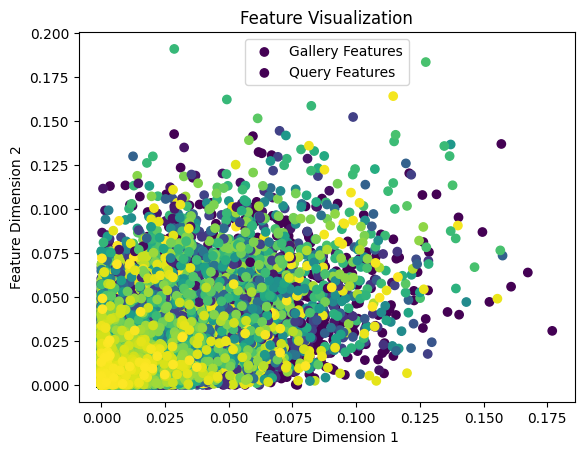

In [47]:
import scipy.io
import matplotlib.pyplot as plt

# Load data from MATLAB file
mat_data = scipy.io.loadmat('model/A/pytorch_result.mat')

# Access features and other relevant information
gallery_features = mat_data['gallery_f']
query_features = mat_data['query_f']
gallery_label = mat_data['gallery_label']
query_label = mat_data['query_label']

# Visualize the features (you may need to customize based on your data structure)
# Example: Scatter plot of features
plt.scatter(gallery_features[:, 0], gallery_features[:, 1], c=gallery_label, cmap='viridis', label='Gallery Features')
plt.scatter(query_features[:, 0], query_features[:, 1], c=query_label, cmap='viridis', label='Query Features')
plt.title('Feature Visualization')
plt.xlabel('Feature Dimension 1')
plt.ylabel('Feature Dimension 2')
plt.legend()
plt.show()


In [50]:
!python3 evaluate_st.py --name A

query_feature: (3368, 12288)
gallery_feature: (19732, 12288)
gauss 0->0
gauss 0->1
gauss 0->2
gauss 0->3
gauss 0->4
gauss 0->5
gauss 0->6
gauss 0->7
gauss 1->0
gauss 1->1
gauss 1->2
gauss 1->3
gauss 1->4
gauss 1->5
gauss 1->6
gauss 1->7
gauss 2->0
gauss 2->1
gauss 2->2
gauss 2->3
gauss 2->4
gauss 2->5
gauss 2->6
gauss 2->7
gauss 3->0
gauss 3->1
gauss 3->2
gauss 3->3
gauss 3->4
gauss 3->5
gauss 3->6
gauss 3->7
gauss 4->0
gauss 4->1
gauss 4->2
gauss 4->3
gauss 4->4
gauss 4->5
gauss 4->6
gauss 4->7
gauss 5->0
gauss 5->1
gauss 5->2
gauss 5->3
gauss 5->4
gauss 5->5
gauss 5->6
gauss 5->7
gauss 6->0
gauss 6->1
gauss 6->2
gauss 6->3
gauss 6->4
gauss 6->5
gauss 6->6
gauss 6->7
gauss 7->0
gauss 7->1
gauss 7->2
gauss 7->3
gauss 7->4
gauss 7->5
gauss 7->6
gauss 7->7
0 tensor(1, dtype=torch.int32)
1 tensor(1, dtype=torch.int32)
2 tensor(1, dtype=torch.int32)
3 tensor(1, dtype=torch.int32)
4 tensor(1, dtype=torch.int32)
5 tensor(1, dtype=torch.int32)
6 tensor(1, dtype=torch.int32)
7 tensor(1, dtype=

In [51]:
import scipy.io

# Load data from MATLAB file
result = scipy.io.loadmat('model/A/pytorch_result.mat')

# Print the keys
print(result.keys())


dict_keys(['__header__', '__version__', '__globals__', 'gallery_f', 'gallery_label', 'gallery_cam', 'gallery_frames', 'query_f', 'query_label', 'query_cam', 'query_frames'])
